# DriftGuard-IoT — paper calculations (CNT 6167, FAU)

Reproduces every number and figure in the paper: the five-seed drift simulation, resource benchmark, SHAP stability, the ESP32 sensor-node circuit and electrical calculations, the dataset map, and the architecture figure.

**All stream data are synthetic** (the repository's generator with injected drift); they are not TON_IoT / WUSTL / Edge-IIoTset results.

Runtime → Run all. Full run ≈ 25–35 min on a free CPU runtime; set `QUICK = True` for one seed.

In [1]:
QUICK = False   # True = one seed, a few minutes

In [2]:
import sys, subprocess
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    subprocess.run('pip -q install --ignore-requires-python "driftguard-iot[explain,platform] @ git+https://github.com/Arungharami/DriftGuard-IoT.git" schemdraw "geopandas<1"', shell=True, check=True)
import driftguard, sklearn, lightgbm, platform
print(platform.python_version(), 'sklearn', sklearn.__version__, 'lightgbm', lightgbm.__version__)

3.11.18 sklearn 1.9.1 lightgbm 4.7.0


## 1. Simulation study code
Uses DriftGuard's own `generate_synthetic_flows`, `delayed_prequential`, `paired_block_interval`, `assess_alarms`, `benchmark_predict`, `defensive_corruption` and `shap_stability`.

In [3]:
"""DriftGuard-IoT controlled simulation study (CNT 6167 paper).

Uses the repository's own synthetic flow generator and M5 evaluation primitives.
All data are SYNTHETIC; results are a controlled simulation, not TON_IoT/WUSTL/Edge evidence.
"""
from __future__ import annotations

import json
import pickle
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.metrics import f1_score
from threadpoolctl import threadpool_limits

from driftguard.config import ModelConfig
from driftguard.data.synthetic import NUMERIC_FEATURES, PROTOCOLS, generate_synthetic_flows
from driftguard.drift.assessment import assess_alarms
from driftguard.m5.evaluation import (
    benchmark_predict,
    defensive_corruption,
    delayed_prequential,
    paired_block_interval,
    shap_stability,
)
from driftguard.models.factory import build_estimator

OUT = Path("results")
OUT.mkdir(parents=True, exist_ok=True)

N = 6000            # flows per stream
INIT = 1000         # initial labelled training flows
GAP = 200           # validation gap (unused by the stream, keeps strict separation)
BATCH = 20          # flows sharing one prediction instant (one "tick")
DELAY = 5           # label delay in ticks (= 100 flows)
ONSET = 0.5         # drift onset as fraction of the stream
PERIOD = 500        # periodic policy: refit after 500 new released labels
SEEDS = [11, 22, 33, 44, 55]
MODELS = ["decision_tree", "random_forest", "lightgbm"]
POLICIES = ["frozen", "periodic", "error_triggered", "adwin", "adwin_window"]
WINDOW = 1000       # adwin_window: refit on the most recent 1000 released rows
FEATURES = [*NUMERIC_FEATURES, *[f"proto_{p}" for p in PROTOCOLS]]


def encode(df: pd.DataFrame) -> tuple[np.ndarray, np.ndarray, list[str]]:
    x = np.log1p(df[list(NUMERIC_FEATURES)].to_numpy(float))
    onehot = np.stack([(df["proto"] == p).to_numpy(float) for p in PROTOCOLS], axis=1)
    return np.hstack([x, onehot]), df["label"].to_numpy(), sorted(df["label"].unique())


def make_stream(seed: int, scenario: str) -> pd.DataFrame:
    total = INIT + GAP + N
    if scenario == "covariate":
        # Repository generator: src_bytes and mean_iat scaled x3 after onset (P(x) changes).
        onset = (INIT + GAP + int(N * ONSET)) / total
        return generate_synthetic_flows(
            total, seed, drift_onset_fraction=onset, drift_scale_multiplier=3.0,
            drift_features=("src_bytes", "mean_iat"),
        )
    # Concept drift: post-onset flows come from a generator with different class-conditional
    # distributions (P(y|x) changes) while class priors stay the same.
    pre_n = INIT + GAP + int(N * ONSET)
    pre = generate_synthetic_flows(total, seed).iloc[:pre_n]
    post = generate_synthetic_flows(total, seed + 1000).iloc[pre_n:]
    return pd.concat([pre, post], ignore_index=True)


def macro(y, p, labels):
    return float(f1_score(y, p, labels=labels, average="macro", zero_division=0))


def run_cell(seed, scenario, model_name):
    df = make_stream(seed, scenario)
    x, y_str, classes = encode(df)
    lut = {c: i for i, c in enumerate(classes)}
    y = np.array([lut[v] for v in y_str], dtype=float)
    ix, iy = x[:INIT], y[:INIT]
    sx, sy = x[INIT + GAP:], y[INIT + GAP:]
    ticks = np.arange(len(sx)) // BATCH + 1000.0
    est = build_estimator(ModelConfig(name=model_name, params={}), seed=seed)
    onset_idx = int(N * ONSET)
    rows, raw = [], {}
    for policy in POLICIES:
        t0 = time.perf_counter()
        r = delayed_prequential(
            est, ix, iy, sx, sy,
            initial_time=np.arange(INIT, dtype=float), event_time=ticks,
            label_time=ticks + DELAY, policy="adwin" if policy == "adwin_window" else policy,
            period=PERIOD, max_retrain_rows=WINDOW if policy == "adwin_window" else None,
            error_window=200, error_threshold=0.30, detector_delta=0.002,
        )
        wall = time.perf_counter() - t0
        p = r["predictions"]
        alarms_t = [a["at"] for a in r["alarms"]]
        change_t = float(ticks[onset_idx])
        assess = None
        if policy.startswith("adwin"):
            assess = assess_alarms(alarms_t, [change_t], horizon=60.0,
                                   stream_start=float(ticks[0]), stream_end=float(ticks[-1]))
        rows.append({
            "seed": seed, "scenario": scenario, "model": model_name, "policy": policy,
            "f1_pre": macro(sy[:onset_idx], p[:onset_idx], list(range(len(classes)))),
            "f1_post": macro(sy[onset_idx:], p[onset_idx:], list(range(len(classes)))),
            "f1_all": macro(sy, p, list(range(len(classes)))),
            "acc_post": float(np.mean(sy[onset_idx:] == p[onset_idx:])),
            "refits": len(r["updates"]),
            "refit_seconds": float(sum(r["refit_seconds"])),
            "wall_seconds": wall,
            "alarms": len(alarms_t),
            "detect_delay_ticks": None if assess is None else assess["delays"][0],
            "false_alarms": None if assess is None else assess["false_alarm_count"],
        })
        raw[policy] = p
    # Paired temporal bootstrap: each policy vs frozen, post-drift segment.
    for row in rows:
        if row["policy"] == "frozen":
            continue
        ci = paired_block_interval(
            sy[onset_idx:], raw["frozen"][onset_idx:], raw[row["policy"]][onset_idx:],
            classes=list(map(float, range(len(classes)))), block_size=100, repeats=500, seed=seed,
        )
        row.update(delta_f1=ci["estimate"], delta_lo=ci["low"], delta_hi=ci["high"])
    # rolling accuracy trace for figure (seed 11, lightgbm only)
    trace = None
    if seed == SEEDS[0] and model_name == "lightgbm":
        w = 300
        trace = {k: pd.Series((v == sy).astype(float)).rolling(w).mean().tolist() for k, v in raw.items()}
    return rows, trace


def resource_bench():
    df = generate_synthetic_flows(INIT + GAP + N, 11)
    x, y_str, classes = encode(df)
    out = []
    for name in ["decision_tree", "random_forest", "bagging", "stacking", "lightgbm"]:
        est = build_estimator(ModelConfig(name=name, params={"cv": 5} if name == "stacking" else {}), seed=11)
        t0 = time.perf_counter(); est.fit(x[:INIT], y_str[:INIT]); fit_s = time.perf_counter() - t0
        b1 = benchmark_predict(est.predict, x[INIT:INIT + 1], repeats=200)
        b256 = benchmark_predict(est.predict, x[INIT:INIT + 256], repeats=100)
        f1 = macro(y_str[INIT + GAP:], est.predict(x[INIT + GAP:]), classes)
        noise = defensive_corruption(
            lambda a, e=est: np.array([classes.index(v) for v in e.predict(a)]),
            x[INIT + GAP:INIT + GAP + 2000], np.array([classes.index(v) for v in y_str[INIT + GAP:INIT + GAP + 2000]]),
            x[:INIT], mutable_columns=list(range(6)), fraction=0.05, seed=11,
        )
        out.append({
            "model": name, "fit_seconds": fit_s, "size_kb": len(pickle.dumps(est)) / 1024,
            "p50_single_ms": b1["p50"] * 1e3, "p95_single_ms": b1["p95"] * 1e3,
            "p50_batch256_ms": b256["p50"] * 1e3, "throughput_rows_s": b256["throughput_rows_per_second"],
            "macro_f1_static": f1, "noise_disagreement": noise["prediction_disagreement"],
            "noise_acc_drop": noise["clean_accuracy"] - noise["corrupted_accuracy"],
        })
    return out


def shap_analysis():
    import shap
    out = {}
    for scenario in ["covariate", "concept"]:
        df = make_stream(11, scenario)
        x, y_str, classes = encode(df)
        est = build_estimator(ModelConfig(name="lightgbm", params={}), seed=11).fit(x[:INIT], y_str[:INIT])
        expl = shap.TreeExplainer(est, data=x[:200], feature_perturbation="interventional")
        s0 = INIT + GAP
        cls = classes.index("dos")
        before = np.asarray(expl.shap_values(x[s0 + 1000:s0 + 1500]))
        after = np.asarray(expl.shap_values(x[s0 + 4000:s0 + 4500]))
        before, after = before[:, :, cls], after[:, :, cls]
        out[scenario] = shap_stability(before, after, feature_names=FEATURES, top_k=3)
    return out




## 2. Run the experiments (writes `results/`)

In [4]:
from pathlib import Path
if QUICK:
    SEEDS = [11]
if Path('results/stream_results.csv').exists() and not QUICK:
    print('results/ already present - delete it to rerun')
else:
    all_rows, traces = [], {}
    with threadpool_limits(limits=1):
        for scenario in ["covariate", "concept"]:
            for model_name in MODELS:
                for seed in SEEDS:
                    rows, trace = run_cell(seed, scenario, model_name)
                    all_rows += rows
                    if trace:
                        traces[scenario] = trace
                    print(scenario, model_name, seed, "done", flush=True)
        res = resource_bench()
        shp = shap_analysis()
    pd.DataFrame(all_rows).to_csv(OUT / "stream_results.csv", index=False)
    pd.DataFrame(res).to_csv(OUT / "resource_results.csv", index=False)
    (OUT / "traces.json").write_text(json.dumps(traces))
    (OUT / "shap.json").write_text(json.dumps(shp, indent=2))
    print("ALL DONE")

results/ already present - delete it to rerun


## 3. Sensor-node circuit, electrical calculations (Table I) and dataset map

In [5]:
"""Edge sensor-node circuit, electrical calculations and geographic map for the paper."""
import json
import sys
import warnings
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import schemdraw
import schemdraw.elements as elm

warnings.filterwarnings("ignore")
OUT = Path("figures")
OUT.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------ electrical calculations
calc = {}
V_BAT_MAX, V_BAT_NOM, V_BAT_MIN = 4.20, 3.70, 3.00     # 18650 Li-ion cell
V_REG, V_DROP = 3.30, 0.178                            # MCP1700 LDO, dropout @ 250 mA
calc["ldo_min_input_V"] = V_REG + V_DROP
calc["ldo_efficiency_nominal_pct"] = 100 * V_REG / V_BAT_NOM

# Status LED (red, Vf = 2.0 V, target 10 mA) from a 3.3 V GPIO
VF, I_LED_TARGET = 2.0, 0.010
R_led_ideal = (V_REG - VF) / I_LED_TARGET
R_LED = 150.0                                          # next E12 value up
calc["led_R_ideal_ohm"] = R_led_ideal
calc["led_R_chosen_ohm"] = R_LED
calc["led_I_mA"] = 1e3 * (V_REG - VF) / R_LED
calc["led_P_resistor_mW"] = 1e3 * ((V_REG - VF) / R_LED) ** 2 * R_LED

# Battery-sense divider into the ESP32 ADC (keep below ~2.45 V at 11 dB attenuation)
R1, R2 = 100e3, 100e3
calc["divider_Vadc_at_4V2"] = V_BAT_MAX * R2 / (R1 + R2)
calc["divider_Vadc_at_3V0"] = V_BAT_MIN * R2 / (R1 + R2)
calc["divider_leak_uA"] = 1e6 * V_BAT_MAX / (R1 + R2)
calc["adc_LSB_mV_battery"] = 1e3 * (2.45 / 4095) * (R1 + R2) / R2

# DHT22 pull-up: 10 kOhm on a 3.3 V line
R_PU = 10e3
calc["dht_pullup_sink_mA"] = 1e3 * V_REG / R_PU

# Duty-cycled power budget: wake every 60 s, sense + MQTT publish for 2 s
I_ACTIVE, T_ACTIVE = 0.120, 2.0                        # ESP32 Wi-Fi TX average (A, s)
I_SLEEP = 10e-6 + calc["divider_leak_uA"] * 1e-6 + 1.6e-6   # deep sleep + divider + LDO Iq
I_SENSOR = 1.5e-3                                      # DHT22 during measurement
T_PERIOD = 60.0
I_avg = ((I_ACTIVE + I_SENSOR) * T_ACTIVE + I_SLEEP * (T_PERIOD - T_ACTIVE)) / T_PERIOD
CAP_mAh, DERATE = 2600.0, 0.80
calc["avg_current_mA"] = I_avg * 1e3
calc["battery_life_hours"] = CAP_mAh * DERATE / (I_avg * 1e3)
calc["battery_life_days"] = calc["battery_life_hours"] / 24
calc["energy_per_report_mJ"] = 1e3 * V_BAT_NOM * (I_ACTIVE + I_SENSOR) * T_ACTIVE
# 5-minute reporting variant
T5 = 300.0
I_avg5 = ((I_ACTIVE + I_SENSOR) * T_ACTIVE + I_SLEEP * (T5 - T_ACTIVE)) / T5
calc["avg_current_mA_5min"] = I_avg5 * 1e3
calc["battery_life_days_5min"] = CAP_mAh * DERATE / (I_avg5 * 1e3) / 24

# MQTT traffic seen by the gateway IDS
PAYLOAD, OVERHEAD = 64, 2 + 20 + 20 + 14           # MQTT fixed hdr+topic, TCP, IPv4, Ethernet-ish
calc["bytes_per_report"] = PAYLOAD + OVERHEAD
NODES = 50
calc["gateway_reports_per_s_50nodes"] = NODES / T_PERIOD
calc["gateway_bitrate_bps_50nodes"] = 8 * calc["bytes_per_report"] * NODES / T_PERIOD

# Raspberry Pi 4 gateway running DriftGuard inference
P_PI = 3.4                                            # W, typical under light CPU load
calc["gateway_daily_energy_Wh"] = P_PI * 24
(OUT / "electrical_calcs.json").write_text(json.dumps(calc, indent=2))

# ------------------------------------------------------------ schematic
with schemdraw.Drawing(file=str(OUT / "fig_circuit.png"), dpi=200, show=False) as d:
    d.config(fontsize=10, unit=2.0)
    # battery and rail
    d.add(elm.Ground().at((0, 0)))
    d.add(elm.BatteryCell().endpoints((0, 0), (0, 2.6)).label(""))
    d.add(elm.Label().at((-1.3, 1.3)).label("18650\nLi-ion\n3.0–4.2 V", fontsize=9.5))
    d.add(elm.Line().endpoints((0, 2.6), (0, 4)))
    d.add(elm.Line().endpoints((0, 4), (2, 4)))
    d.add(elm.Dot().at((2, 4)))
    # battery-sense divider
    d.add(elm.Resistor().endpoints((2, 4), (2, 2)).label("R1\n100 kΩ", loc="bottom"))
    d.add(elm.Dot().at((2, 2)))
    d.add(elm.Resistor().endpoints((2, 2), (2, 0)).label("R2\n100 kΩ", loc="bottom"))
    d.add(elm.Ground().at((2, 0)))
    # LDO
    d.add(elm.Line().endpoints((2, 4), (3.6, 4)))
    ldo = d.add(elm.Ic(pins=[elm.IcPin("IN", side="left"), elm.IcPin("GND", side="bottom"),
                              elm.IcPin("OUT", side="right")], size=(2.2, 1.6), pinlblsize=8,
                       plblofst=0.08).anchor("IN").at((3.6, 4)))
    d.add(elm.Label().at((ldo.center[0], ldo.center[1] + 1.3)).label("MCP1700 LDO\n3.3 V", fontsize=9.5))
    d.add(elm.Ground().at(ldo.GND))
    ox = ldo.OUT[0]
    d.add(elm.Line().endpoints(ldo.OUT, (ox + 1.0, 4)))
    d.add(elm.Dot().at((ox + 1.0, 4)).label("3V3", loc="top"))
    d.add(elm.Capacitor().endpoints((ox + 1.0, 4), (ox + 1.0, 2.9)).label("C1 10 µF", loc="bottom"))
    d.add(elm.Ground().at((ox + 1.0, 2.9)))
    vx = ox + 2.6                       # DHT22 VCC tap on the rail
    ex = vx + 3.4                       # ESP32 left edge pins
    d.add(elm.Line().endpoints((ox + 1.0, 4), (ex, 4)))
    d.add(elm.Dot().at((vx, 4)))
    # ESP32 (left pins bottom->top: ADC, 3V3, GPIO4)
    mcu = d.add(elm.Ic(
        pins=[elm.IcPin("GPIO34 (ADC)", side="left", slot="1/3"), elm.IcPin("3V3", side="left", slot="2/3"),
              elm.IcPin("GPIO4", side="left", slot="3/3"), elm.IcPin("GPIO2", side="right", slot="1/2"),
              elm.IcPin("ANT", side="right", slot="2/2"), elm.IcPin(name="", anchorname="GND", side="bottom")],
        size=(6.0, 3.6), pinlblsize=9, label="").anchor("3V3").at((ex, 4)))
    d.add(elm.Ground().at(mcu.GND))
    d.add(elm.Label().at((mcu.center[0], mcu.center[1] + 0.25)).label("ESP32-WROOM\nsensor node", fontsize=11.5))
    d.add(elm.Line().endpoints(mcu.ANT, (mcu.ANT[0] + 0.8, mcu.ANT[1])))
    d.add(elm.Antenna().at((mcu.ANT[0] + 0.8, mcu.ANT[1])).label("Wi-Fi: MQTT/TCP to\nDriftGuard gateway", loc="right", ofst=0.2))
    # ADC route from divider midpoint
    ay = mcu["GPIO34 (ADC)"][1]
    d.add(elm.Line().endpoints((2, 2), (ex - 0.6, 2)).color("#1f5fa8"))
    d.add(elm.Line().endpoints((ex - 0.6, 2), (ex - 0.6, ay)).color("#1f5fa8"))
    d.add(elm.Line().endpoints((ex - 0.6, ay), mcu["GPIO34 (ADC)"]).color("#1f5fa8"))
    # DHT22 above the rail
    gy = mcu.GPIO4[1]
    dx_data = vx + 1.8
    top_y = gy + 2.6
    d.add(elm.Line().endpoints((vx, 4), (vx, top_y)))
    d.add(elm.Line().endpoints((dx_data, gy), (dx_data, top_y)).color("#b03a2e"))
    d.add(elm.Line().endpoints((dx_data, gy), mcu.GPIO4).color("#b03a2e"))
    d.add(elm.Resistor().endpoints((vx, gy + 1.2), (dx_data, gy + 1.2)).label("10 kΩ pull-up", loc="top", fontsize=9))
    d.add(elm.Dot().at((vx, gy + 1.2)))
    d.add(elm.Dot().at((dx_data, gy + 1.2)))
    # DHT22 box drawn as rectangle with three bottom pins
    bx0, bx1 = vx - 0.6, dx_data + 1.8
    d.add(elm.Line().endpoints((bx0, top_y), (bx1, top_y)))
    d.add(elm.Line().endpoints((bx1, top_y), (bx1, top_y + 1.1)))
    d.add(elm.Line().endpoints((bx1, top_y + 1.1), (bx0, top_y + 1.1)))
    d.add(elm.Line().endpoints((bx0, top_y + 1.1), (bx0, top_y)))
    d.add(elm.Label().at(((bx0 + bx1) / 2, top_y + 0.75)).label("DHT22 temp./humidity sensor", fontsize=9.5))
    d.add(elm.Label().at((vx, top_y + 0.25)).label("VCC", fontsize=8))
    d.add(elm.Label().at((dx_data, top_y + 0.25)).label("DATA", fontsize=8))
    d.add(elm.Label().at((dx_data + 1.2, top_y + 0.25)).label("GND", fontsize=8))
    d.add(elm.Line().endpoints((dx_data + 1.2, top_y), (dx_data + 1.2, top_y - 0.5)))
    d.add(elm.Ground().at((dx_data + 1.2, top_y - 0.5)))
    # status LED
    lx = mcu.GPIO2[0]
    d.add(elm.Line().endpoints(mcu.GPIO2, (lx + 0.5, mcu.GPIO2[1])))
    d.add(elm.Resistor().right().at((lx + 0.5, mcu.GPIO2[1])).label("R_LED 150 Ω", loc="top"))
    d.add(elm.LED().down().label("red LED\n8.7 mA", loc="bottom"))
    d.add(elm.Ground())

# ------------------------------------------------------------ geographic map
import geopandas as gpd

world = gpd.read_file(gpd.datasets.get_path("naturalearth_lowres"))
sites = [
    ("TON_IoT\nUNSW Canberra, AU", 149.13, -35.28, "#c0392b"),
    ("WUSTL-IIoT-2021\nWashington Univ., St. Louis, US", -90.31, 38.65, "#d68910"),
    ("Edge-IIoTset\nUniv. of Guelma, DZ", 7.43, 36.46, "#7d3c98"),
    ("Edge-IIoTset co-authors\nDe Montfort Univ., UK", -1.14, 52.63, "#7d3c98"),
    ("This study\nFAU, Boca Raton, US", -80.10, 26.37, "#1e8449"),
]
fig, ax = plt.subplots(figsize=(11, 5.6), dpi=200)
world[world.continent != "Antarctica"].plot(ax=ax, color="#e8ecef", edgecolor="#9aa5ad", linewidth=0.4)
fx, fy = -80.10, 26.37
for name, x, y, c in sites:
    if "FAU" not in name:
        ax.annotate("", xy=(fx, fy), xytext=(x, y),
                    arrowprops=dict(arrowstyle="->", color=c, lw=1.1, alpha=0.55,
                                    connectionstyle="arc3,rad=0.18"))
    ax.scatter(x, y, s=70 if "FAU" in name else 45, color=c, edgecolor="black", zorder=5,
               marker="*" if "FAU" in name else "o")
offsets = {"TON_IoT": (-90, -32), "WUSTL": (-200, 15), "Edge-IIoTset\nUniv": (12, -28),
           "Edge-IIoTset co": (10, 14), "This study": (12, -26)}
for name, x, y, c in sites:
    key = next(k for k in offsets if name.startswith(k))
    ax.annotate(name, (x, y), xytext=offsets[key], textcoords="offset points", fontsize=8.5,
                color=c, fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.25", fc="white", ec=c, lw=0.6, alpha=0.9))
ax.set_xlim(-170, 180); ax.set_ylim(-58, 80)
ax.set_xlabel("Longitude (°)"); ax.set_ylabel("Latitude (°)")
ax.set_title("Origin of the three IoT/IIoT benchmark datasets and the study site", fontsize=12)
ax.grid(alpha=0.25, lw=0.4)
fig.tight_layout(); fig.savefig(OUT / "fig_map.png"); plt.close(fig)

# great-circle distances to FAU (haversine)
import math
def hav(a, b, c, d):
    r = 6371.0; p1, p2 = math.radians(b), math.radians(d)
    dp, dl = p2 - p1, math.radians(c - a)
    h = math.sin(dp / 2) ** 2 + math.cos(p1) * math.cos(p2) * math.sin(dl / 2) ** 2
    return 2 * r * math.asin(math.sqrt(h))
dist = {n.split("\n")[0]: round(hav(x, y, fx, fy)) for n, x, y, _ in sites if "FAU" not in n}
(OUT / "map_distances_km.json").write_text(json.dumps(dist, indent=2))
print(json.dumps(calc, indent=2)); print(dist)


{
  "ldo_min_input_V": 3.4779999999999998,
  "ldo_efficiency_nominal_pct": 89.18918918918918,
  "led_R_ideal_ohm": 129.99999999999997,
  "led_R_chosen_ohm": 150.0,
  "led_I_mA": 8.666666666666664,
  "led_P_resistor_mW": 11.266666666666667,
  "divider_Vadc_at_4V2": 2.1,
  "divider_Vadc_at_3V0": 1.5,
  "divider_leak_uA": 21.0,
  "adc_LSB_mV_battery": 1.1965811965811965,
  "dht_pullup_sink_mA": 0.33,
  "avg_current_mA": 4.0815133333333335,
  "battery_life_hours": 509.6148977421773,
  "battery_life_days": 21.23395407259072,
  "energy_per_report_mJ": 899.1,
  "avg_current_mA_5min": 0.8423826666666667,
  "battery_life_days_5min": 102.88277536574826,
  "bytes_per_report": 120,
  "gateway_reports_per_s_50nodes": 0.8333333333333334,
  "gateway_bitrate_bps_50nodes": 800.0,
  "gateway_daily_energy_Wh": 81.6
}
{'TON_IoT': 15260, 'WUSTL-IIoT-2021': 1665, 'Edge-IIoTset': 8100, 'Edge-IIoTset co-authors': 6983}


## 4. Architecture figure

In [6]:
import sys
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

OUT = Path("figures")
fig, ax = plt.subplots(figsize=(12, 5.2), dpi=200)
ax.set_xlim(0, 12); ax.set_ylim(0, 5.2); ax.axis("off")

def box(x, y, w, h, text, fc, ec="#34495e", fs=9.5, bold=False):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.04,rounding_size=0.12",
                                fc=fc, ec=ec, lw=1.2))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs,
            fontweight="bold" if bold else "normal", wrap=True)

def arrow(a, b, text="", color="#2c3e50", rad=0.0, ls="-", toff=(0, 0.12)):
    ax.add_patch(FancyArrowPatch(a, b, arrowstyle="-|>", mutation_scale=13, lw=1.4, color=color,
                                 connectionstyle=f"arc3,rad={rad}", linestyle=ls))
    if text:
        ax.text((a[0] + b[0]) / 2 + toff[0], (a[1] + b[1]) / 2 + toff[1], text, ha="center",
                fontsize=8, color=color, style="italic")

# tiers
for x, w, t in [(0.1, 2.4, "Perception tier"), (2.8, 1.9, "Network tier"), (5.0, 6.9, "Edge gateway tier (DriftGuard)")]:
    ax.add_patch(FancyBboxPatch((x, 0.15), w, 4.85, boxstyle="round,pad=0.02", fc="#f7f9fa", ec="#bdc3c7", lw=0.8, ls="--"))
    ax.text(x + w / 2, 4.78, t, ha="center", fontsize=10, fontweight="bold", color="#566573")

for i, y in enumerate([3.55, 2.45, 1.35]):
    box(0.35, y, 1.9, 0.75, f"ESP32 node {i + 1}\nDHT22 + battery ADC", "#d6eaf8", fs=8.5)
box(3.0, 2.2, 1.5, 1.1, "MQTT broker\n(TCP/1883)", "#fdebd0")
for y in [3.9, 2.8, 1.7]:
    arrow((2.25, y), (3.0, 2.75), rad=0.0)

box(5.25, 2.2, 1.55, 1.1, "Flow feature\nextraction\n(log + one-hot)", "#e8f8f5", fs=8.5)
box(7.1, 2.2, 1.6, 1.1, "Tree / LightGBM\nclassifier\n(frozen fit)", "#d5f5e3", fs=8.5, bold=True)
box(9.05, 2.2, 1.6, 1.1, "Alert / dashboard\n(predicted class)", "#fadbd8", fs=8.5)
arrow((4.5, 2.75), (5.25, 2.75), "flows")
arrow((6.8, 2.75), (7.1, 2.75))
arrow((8.7, 2.75), (9.05, 2.75))

box(9.05, 0.45, 2.6, 1.0, "Delayed labels\n(analyst / ground truth,\nreleased after Δ = 5 ticks)", "#fcf3cf", fs=8.2)
box(5.25, 0.45, 3.45, 1.0, "ADWIN monitor on released errors\n(δ = 0.002, each error seen once)", "#ebdef0", fs=8.5)
arrow((9.05, 0.95), (8.7, 0.95), "errors")
box(5.25, 3.65, 3.45, 0.95, "Windowed refit: clone pipeline,\nfit on last W = 1000 released rows", "#d6eaf8", fs=8.5)
ax.plot([5.4, 5.4, 5.12, 5.12], [1.45, 1.75, 1.75, 4.1], color="#7d3c98", lw=1.4, ls="--")
arrow((5.1, 4.1), (5.26, 4.1), color="#7d3c98")
ax.text(5.15, 1.85, "alarm", fontsize=8, color="#7d3c98", style="italic", rotation=90, va="bottom")
arrow((7.9, 2.2), (7.9, 1.45), "", color="#2c3e50")
ax.text(7.97, 1.75, "predictions", fontsize=8, color="#2c3e50", style="italic")
arrow((7.9, 3.65), (7.9, 3.3), "new model", color="#1f5fa8", toff=(0.55, -0.1))
fig.tight_layout(); fig.savefig(OUT / "fig_architecture.png"); plt.close(fig)


## 5. Result tables and figures (Tables II–IV, Figs. 4–6)

In [7]:
"""Summaries and result figures for the paper."""
import json
import sys
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RES = Path("results")
FIG = Path("figures")
FIG.mkdir(exist_ok=True)
df = pd.read_csv(RES / "stream_results.csv")
order = ["frozen", "periodic", "error_triggered", "adwin", "adwin_window"]
names = {"frozen": "Frozen", "periodic": "Periodic", "error_triggered": "Error-threshold",
         "adwin": "ADWIN", "adwin_window": "ADWIN-window"}
mnames = {"decision_tree": "Decision Tree", "random_forest": "Random Forest", "lightgbm": "LightGBM"}

g = df.groupby(["scenario", "model", "policy"])
summ = g.agg(f1_pre=("f1_pre", "mean"), f1_post=("f1_post", "mean"), f1_post_sd=("f1_post", "std"),
             delta=("delta_f1", "mean"), delta_sd=("delta_f1", "std"),
             ci_excl0=("delta_lo", lambda s: int((s > 0).sum())),
             refits=("refits", "mean"), refit_s=("refit_seconds", "mean"),
             alarms=("alarms", "mean"), delay=("detect_delay_ticks", "mean"),
             fa=("false_alarms", "mean")).reset_index()
summ.to_csv(RES / "summary_by_cell.csv", index=False)
pd.set_option("display.width", 200)
print(summ.round(3).to_string())

# averaged over models
pol = df.groupby(["scenario", "policy"]).agg(
    f1_post=("f1_post", "mean"), f1_post_sd=("f1_post", "std"), refits=("refits", "mean"),
    refit_s=("refit_seconds", "mean"), delta=("delta_f1", "mean")).reset_index()
print(pol.round(3).to_string())
pol.to_csv(RES / "summary_by_policy.csv", index=False)

# share of post-drift loss recovered relative to periodic, per scenario/model
rec = []
for (sc, m), sub in summ.groupby(["scenario", "model"]):
    s = sub.set_index("policy")
    fz, pe = s.loc["frozen", "f1_post"], s.loc["periodic", "f1_post"]
    for p in ["adwin", "adwin_window", "error_triggered"]:
        rec.append({"scenario": sc, "model": m, "policy": p,
                    "gain_vs_periodic_gain": (s.loc[p, "f1_post"] - fz) / (pe - fz) if pe != fz else np.nan,
                    "refit_seconds_ratio": s.loc[p, "refit_s"] / s.loc["periodic", "refit_s"]})
rec = pd.DataFrame(rec); rec.to_csv(RES / "recovery.csv", index=False)
print(rec.round(3).to_string())

# ---- Fig 4: post-drift macro-F1 by policy, model, scenario
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), dpi=200, sharey=True)
colors = ["#7f8c8d", "#2e86c1", "#e67e22", "#8e44ad", "#27ae60"]
for ax, sc in zip(axes, ["covariate", "concept"]):
    sub = summ[summ.scenario == sc]
    x = np.arange(3); w = 0.16
    for i, p in enumerate(order):
        vals = [sub[(sub.model == m) & (sub.policy == p)].f1_post.item() for m in mnames]
        sds = [sub[(sub.model == m) & (sub.policy == p)].f1_post_sd.item() for m in mnames]
        ax.bar(x + (i - 2) * w, vals, w, yerr=sds, capsize=2, color=colors[i], label=names[p],
               error_kw=dict(lw=0.8))
    ax.set_xticks(x, list(mnames.values()))
    ax.set_title(f"{'Covariate' if sc == 'covariate' else 'Concept'} drift", fontsize=11)
    ax.grid(axis="y", alpha=0.3); ax.set_ylim(0, 1)
axes[0].set_ylabel("Post-drift macro-F1 (mean ± SD, 5 seeds)")
axes[1].legend(fontsize=8, loc="upper right", ncol=1)
fig.tight_layout(); fig.savefig(FIG / "fig_f1_post.png"); plt.close(fig)

# ---- Fig 5: rolling accuracy traces (LightGBM, seed 11)
tr = json.loads((RES / "traces.json").read_text())
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), dpi=200, sharey=True)
for ax, sc in zip(axes, ["covariate", "concept"]):
    for i, p in enumerate(order):
        y = np.array(tr[sc][p], dtype=float)
        ax.plot(np.arange(len(y)), y, color=colors[i], lw=1.2, label=names[p])
    ax.axvline(3000, color="black", ls="--", lw=1); ax.text(3050, 0.32, "drift onset", fontsize=8)
    ax.set_title(f"{'Covariate' if sc == 'covariate' else 'Concept'} drift (LightGBM, seed 11)", fontsize=10)
    ax.set_xlabel("Flow index in stream"); ax.grid(alpha=0.3); ax.set_ylim(0.3, 1.0)
axes[0].set_ylabel("Rolling accuracy (300 flows)")
axes[1].legend(fontsize=8, loc="lower left")
fig.tight_layout(); fig.savefig(FIG / "fig_traces.png"); plt.close(fig)

# ---- Fig 6: cost vs benefit (concept drift)
fig, ax = plt.subplots(figsize=(6.4, 4.2), dpi=200)
marks = {"decision_tree": "o", "random_forest": "s", "lightgbm": "^"}
for sc, fill in [("concept", True), ("covariate", False)]:
    sub = summ[summ.scenario == sc]
    for i, p in enumerate(order[1:], start=1):
        for m in mnames:
            r = sub[(sub.model == m) & (sub.policy == p)].iloc[0]
            ax.scatter(r.refit_s + 1e-3, r.delta, marker=marks[m], s=45,
                       facecolor=colors[i] if fill else "white", edgecolor=colors[i], lw=1.3)
ax.set_xscale("log"); ax.axhline(0, color="black", lw=0.7)
ax.set_xlabel("Total retraining time per stream (s, log scale)")
ax.set_ylabel("Post-drift macro-F1 gain over frozen")
from matplotlib.lines import Line2D
h = [Line2D([], [], marker="o", ls="", color=colors[i], label=names[p]) for i, p in enumerate(order) if i]
h += [Line2D([], [], marker=marks[m], ls="", color="gray", label=mnames[m]) for m in mnames]
h += [Line2D([], [], marker="o", ls="", mfc="white", color="gray", label="open = covariate")]
ax.legend(handles=h, fontsize=7.5, loc="lower right", ncol=2); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(FIG / "fig_cost_benefit.png"); plt.close(fig)

res = pd.read_csv(RES / "resource_results.csv")
print(res.round(4).to_string())
print(json.loads((RES / "shap.json").read_text()))


     scenario          model           policy  f1_pre  f1_post  f1_post_sd  delta  delta_sd  ci_excl0  refits  refit_s  alarms  delay   fa
0     concept  decision_tree            adwin   0.878    0.450       0.119  0.210     0.191         5     1.2    0.027     1.2   7.40  0.0
1     concept  decision_tree     adwin_window   0.878    0.569       0.096  0.329     0.171         5     1.6    0.009     1.6   7.40  0.0
2     concept  decision_tree  error_triggered   0.878    0.595       0.058  0.354     0.134         5     3.4    0.103     0.0    NaN  NaN
3     concept  decision_tree           frozen   0.878    0.240       0.079    NaN       NaN         0     0.0    0.000     0.0    NaN  NaN
4     concept  decision_tree         periodic   0.893    0.596       0.045  0.356     0.113         5    11.0    0.250     0.0    NaN  NaN
5     concept       lightgbm            adwin   0.934    0.526       0.204  0.277     0.277         5     1.6    0.408     1.6   7.00  0.2
6     concept       lightgb

           model  fit_seconds    size_kb  p50_single_ms  p95_single_ms  p50_batch256_ms  throughput_rows_s  macro_f1_static  noise_disagreement  noise_acc_drop
0  decision_tree       0.0052    14.9502         0.1005         0.1461           0.0972       2.507119e+06           0.7828              0.0150          0.0000
1  random_forest       0.2203  1429.4980         4.7406         8.1000           6.3482       3.818011e+04           0.8730              0.0040         -0.0035
2        bagging       0.0689   106.4678         1.3203         2.0585           1.8798       1.339147e+05           0.8367              0.0135          0.0025
3       stacking       1.8345  1499.1143         5.7704         9.1212           7.2176       3.373363e+04           0.8682              0.0080         -0.0020
4       lightgbm       0.1692  1338.5127         0.7037         0.9689           8.6564       2.934772e+04           0.8722              0.0115          0.0025
{'covariate': {'status': 'measured', 'to

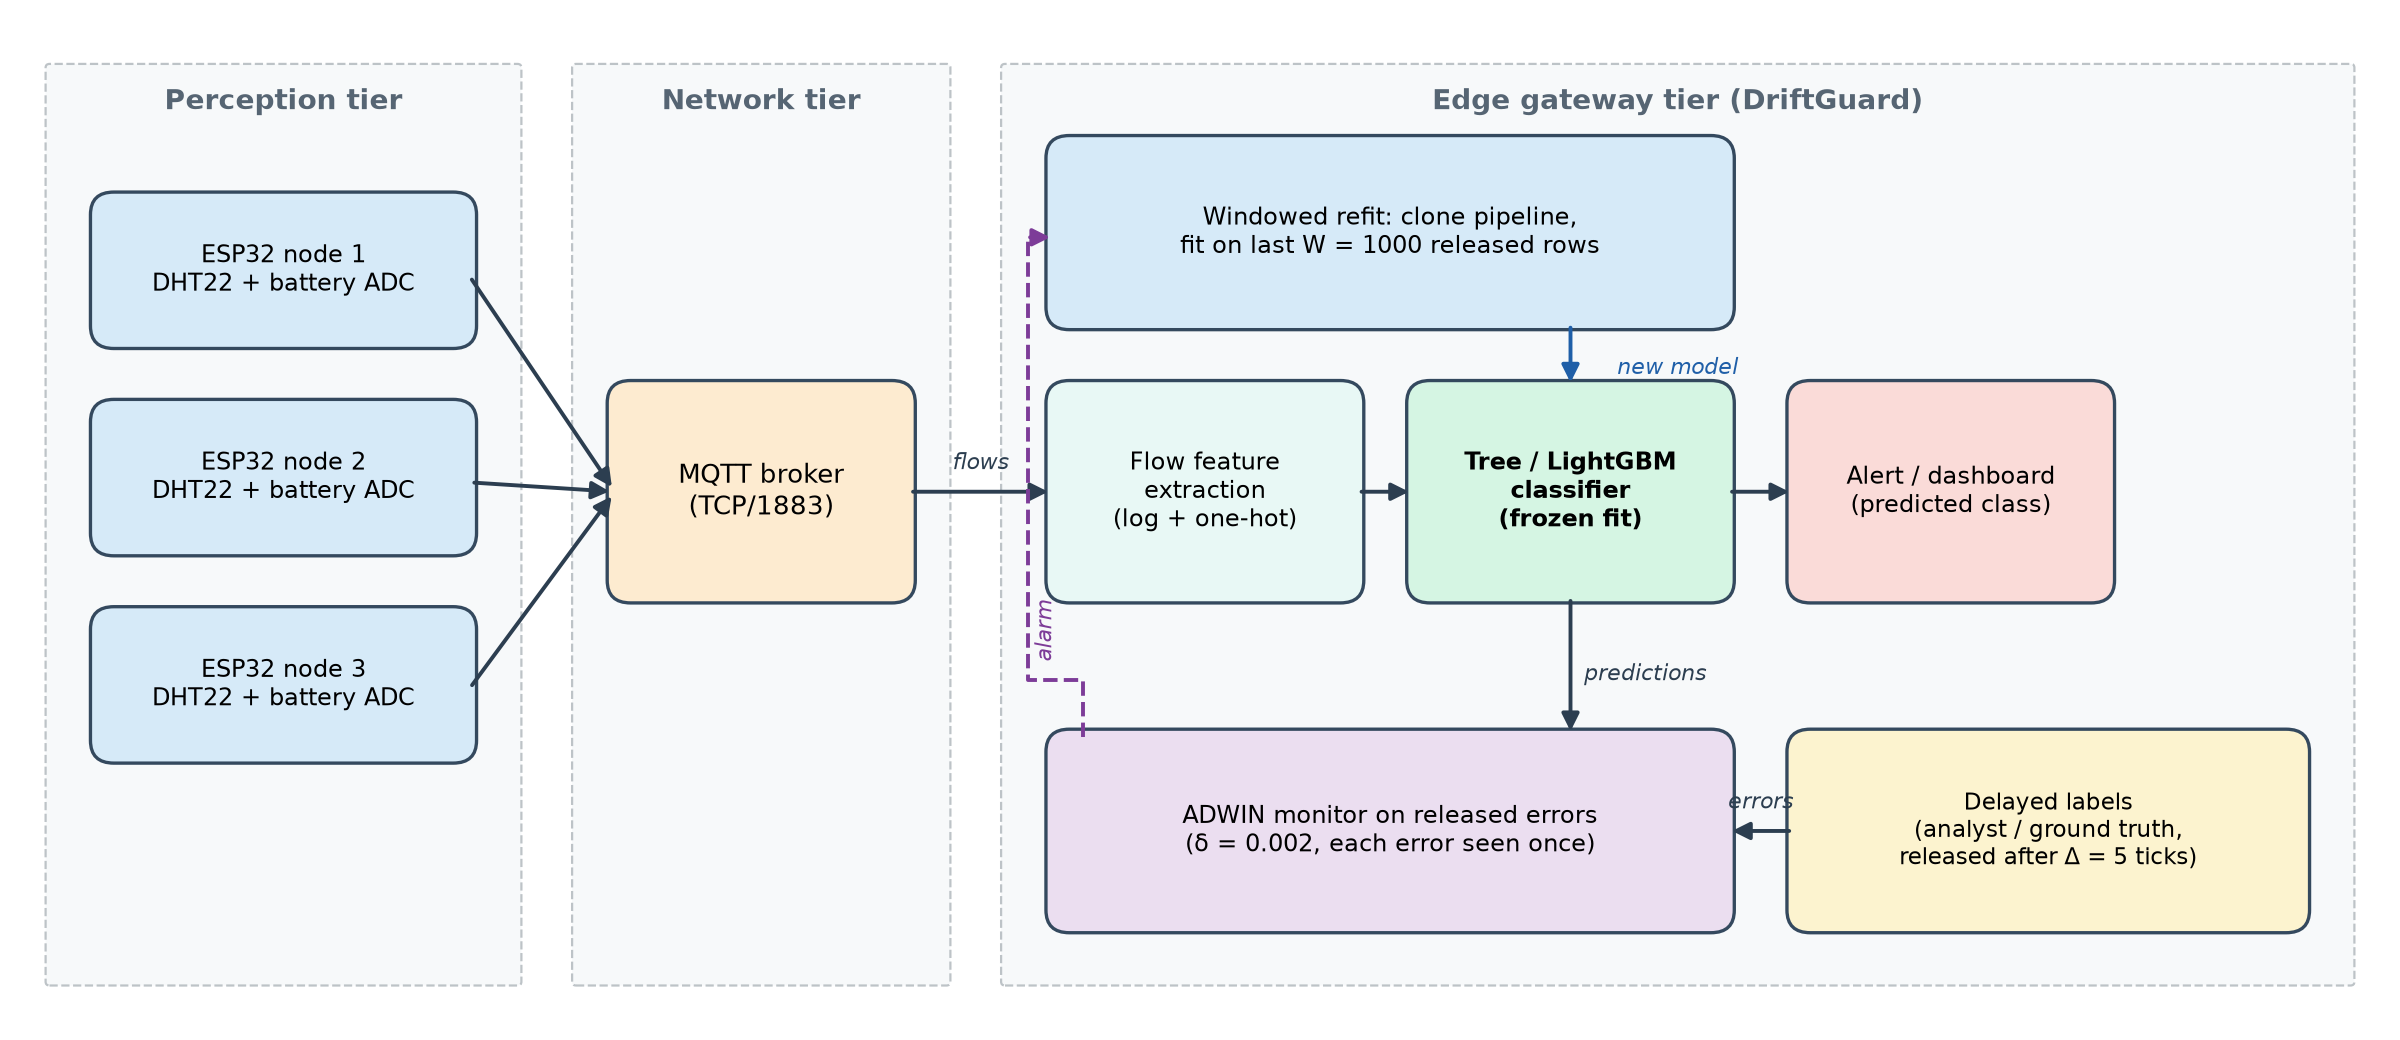

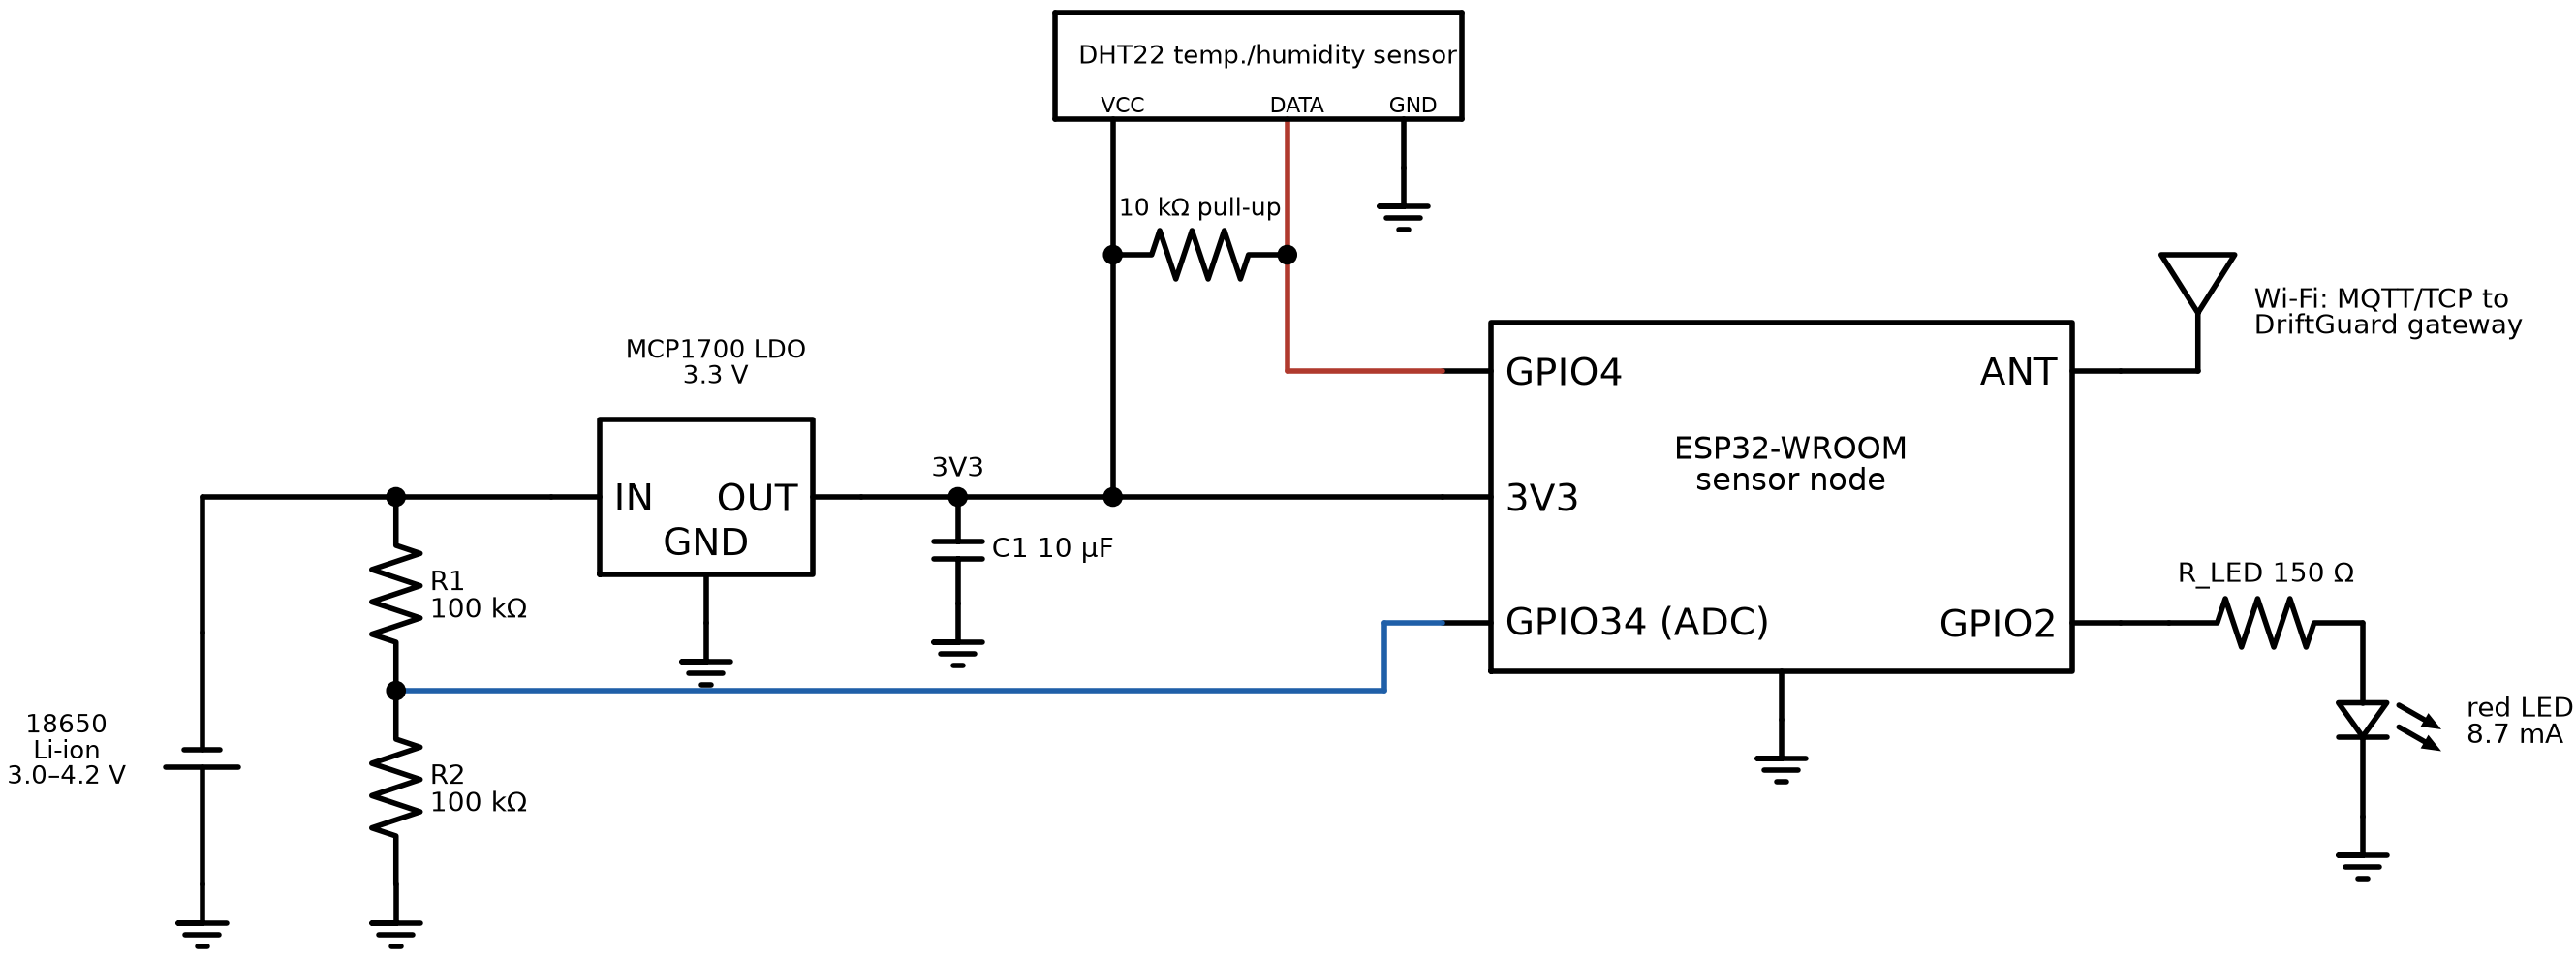

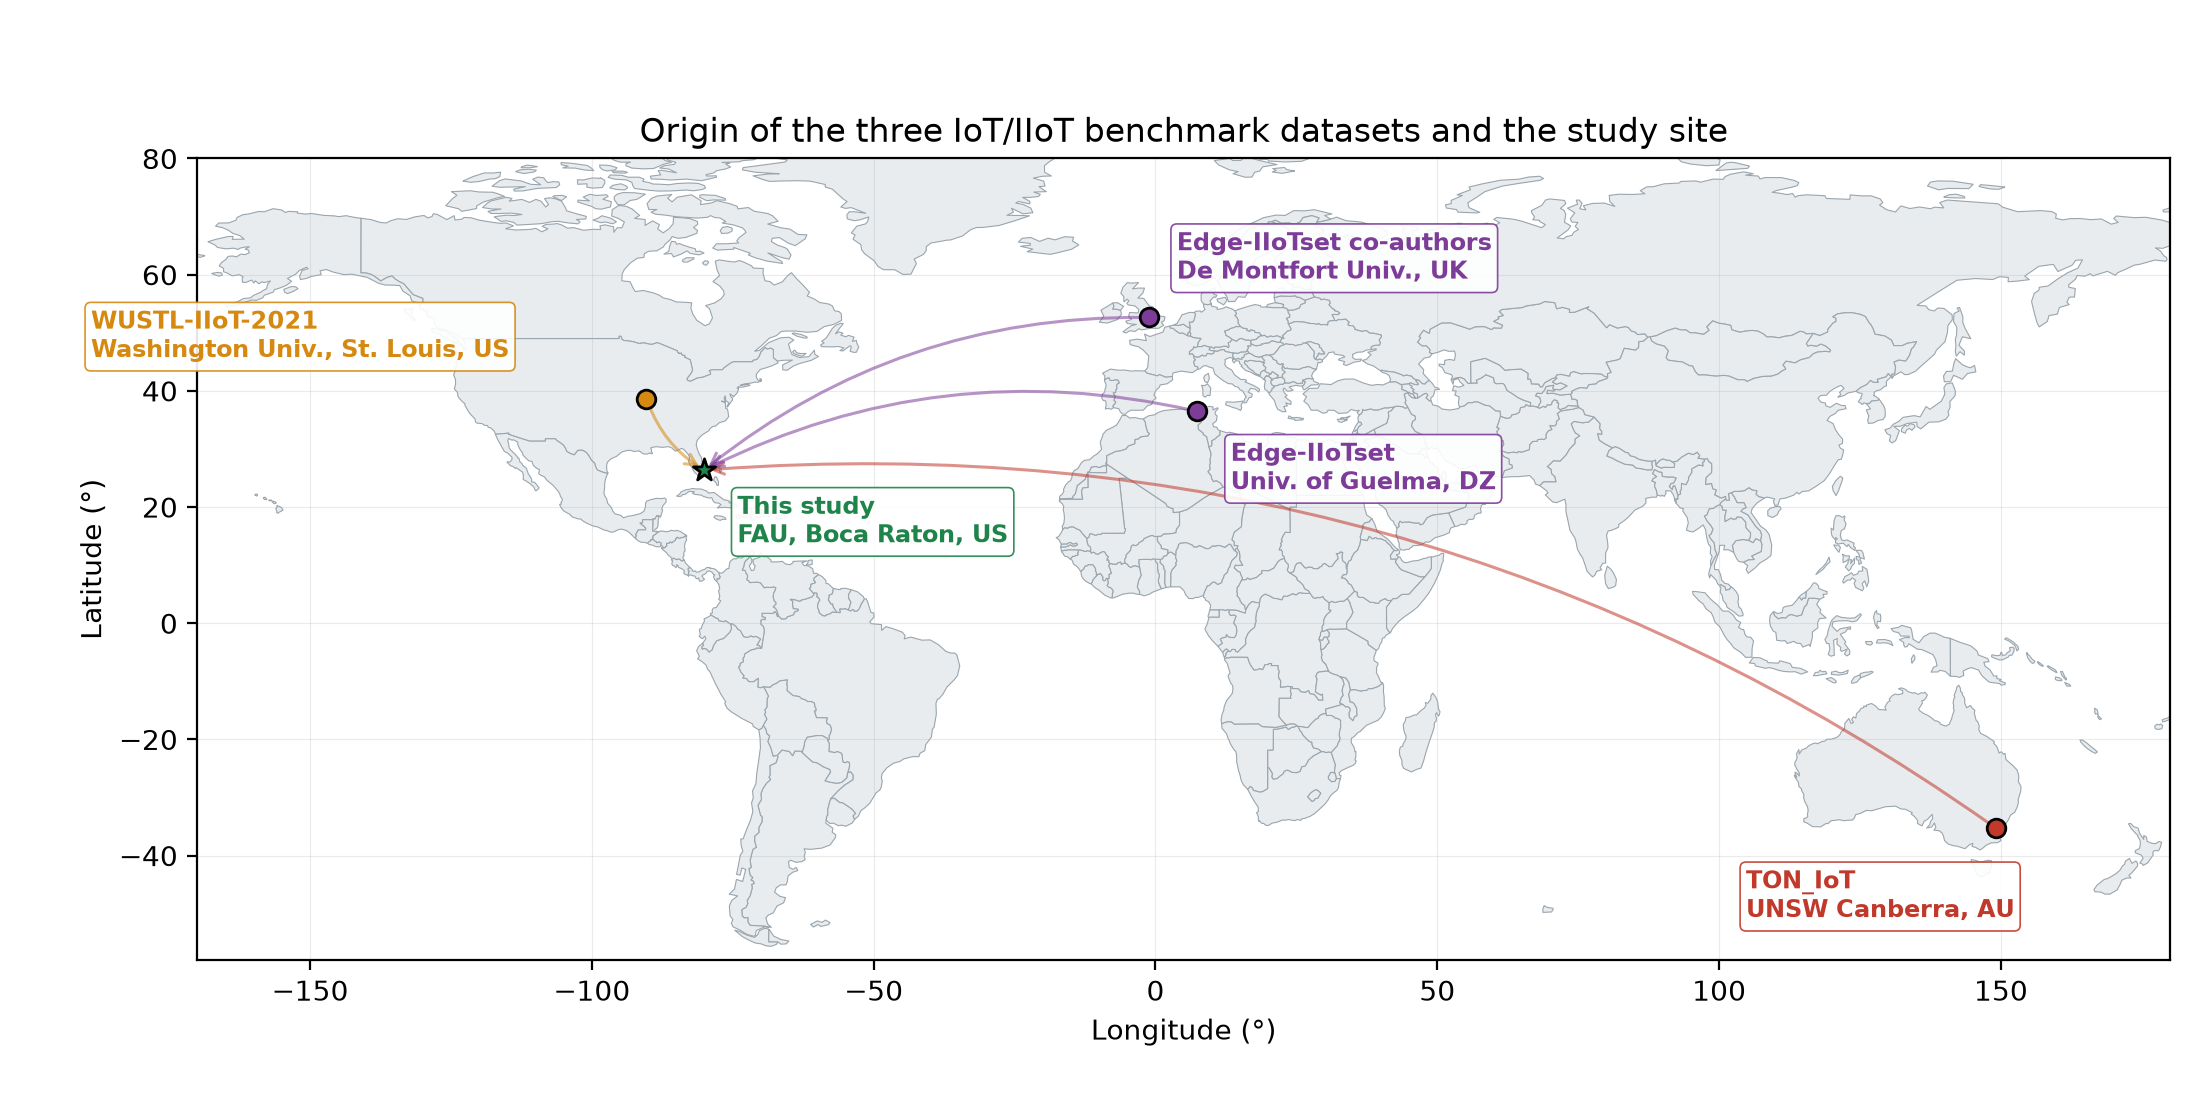

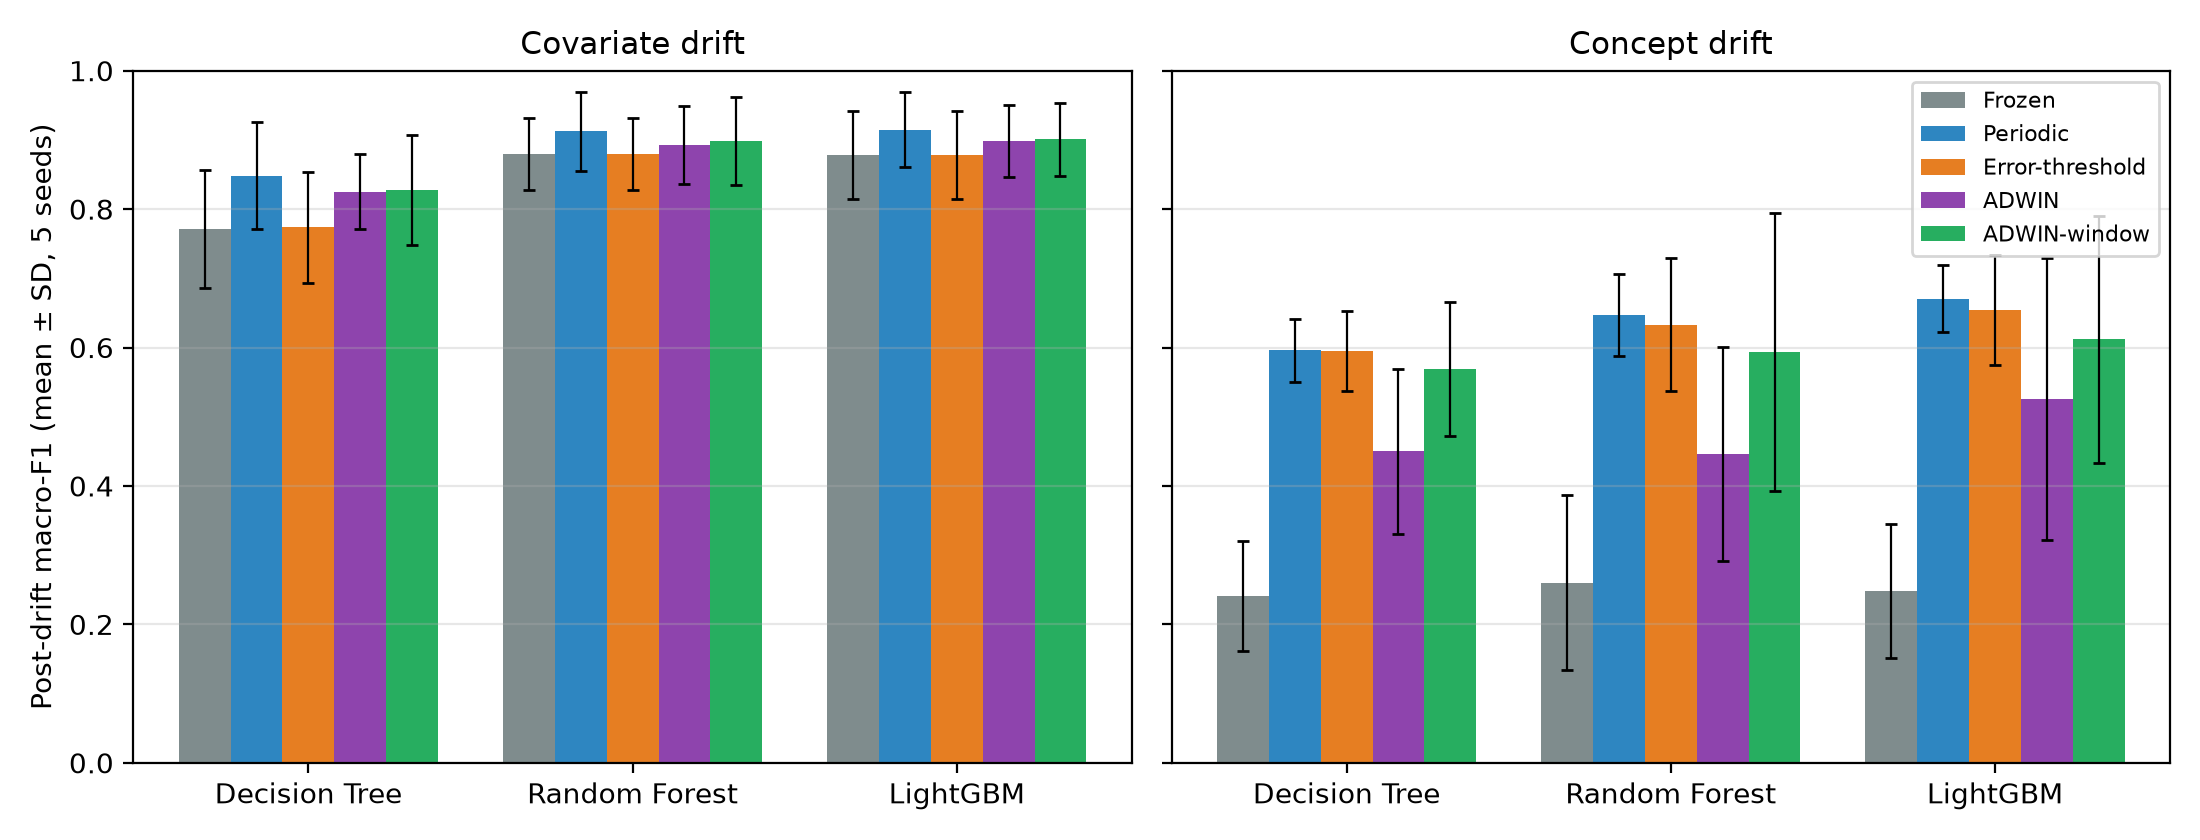

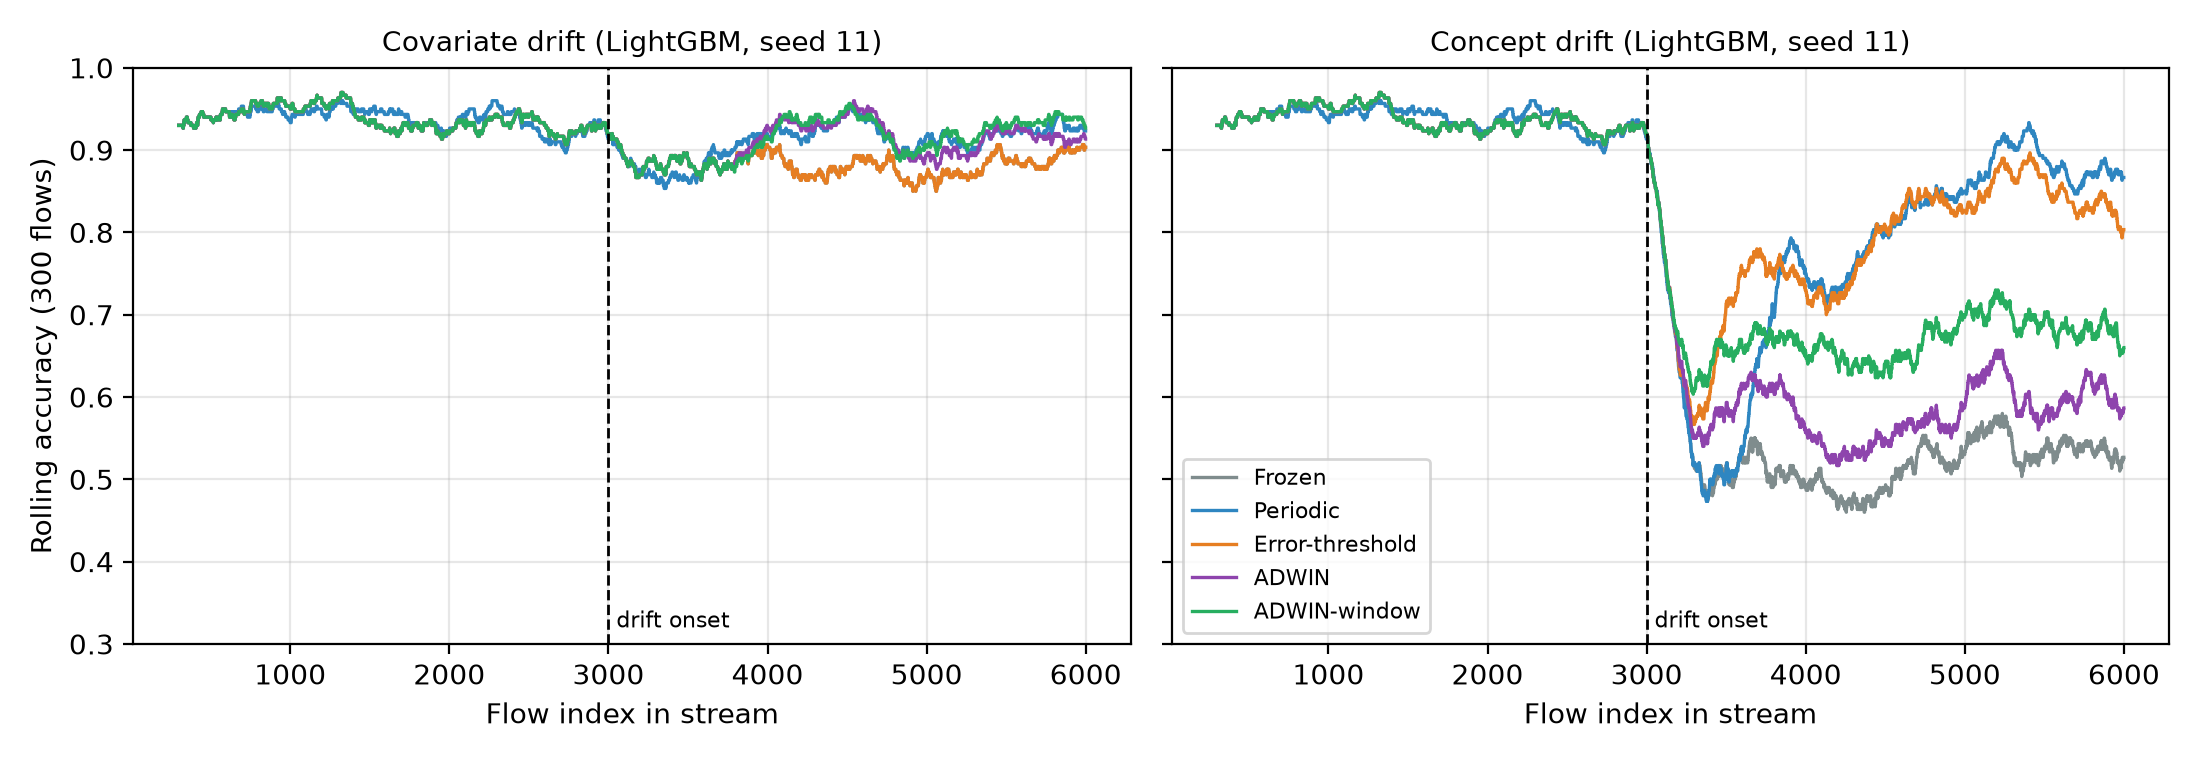

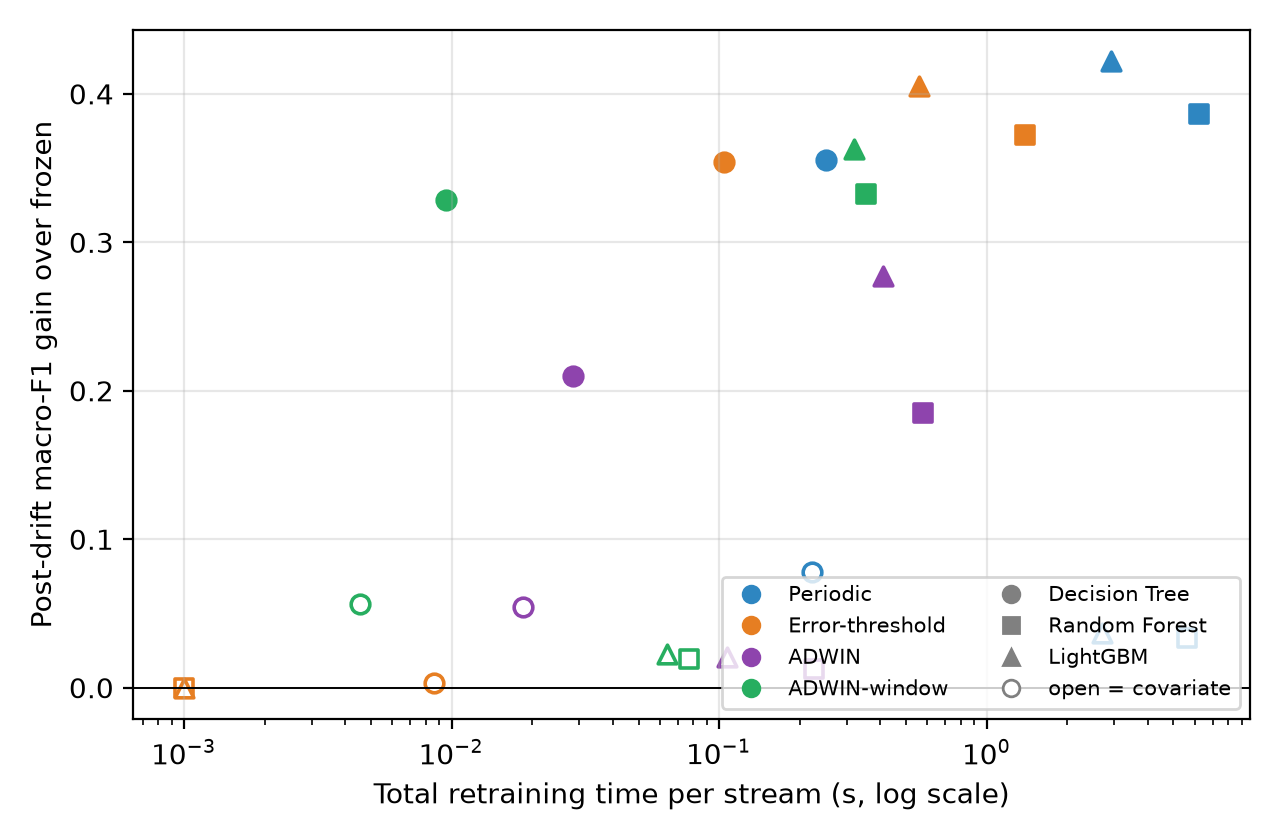

In [8]:
from IPython.display import Image, display
for f in ['fig_architecture','fig_circuit','fig_map','fig_f1_post','fig_traces','fig_cost_benefit']:
    display(Image(f'figures/{f}.png', width=900))